# Closing-line backtest

This notebook asks whether the game simulator would have made money betting
player props at the historical closing line. It is a walk-forward, not a
single fit. Moneylines, spreads, and totals are not graded.

For a slate on November 5, every model is fit on games through November 4.
November 5 scores are not inputs. The Pinnacle closing total and home
spread condition Layer 1. The Rotowire confirmed five sets who starts in
Layer 3. Prop prices are attached after the simulations exist, and the
final box score is used only to settle the bet.

## What a bet is

`EV = model_win_probability * decimal_odds - 1` when the line cannot push.
An integer line can push. The stake is returned on a push, so that slice of
probability adds no profit and no loss. With a push probability `q`, the
same formula is `win_probability * decimal_odds - (1 - q)`.

The bet price is the American close in each book's `closing/` player-prop
files. `team_closing_lines/` is the Layer 1 number, not a bet. The file date
is the Pacific slate date. `closing_fetched_at` is the last snapshot that
still listed the player or game, taken before the next snapshot dropped it
at tip. A UTC timestamp after midnight can still belong to the previous
Pacific evening. The open is ignored. A book with no prop price is skipped
and counted. Another book's price is not filled in.

Player props keep one two-way rung per player and stat: the over/under pair
whose implied probabilities are closest. Other rungs are alternates and are
not bet. A line with no American price is excluded. PrizePicks standard lines in
this archive have no side and no price, so both sides are filled at -119.
Demon and goblin lines stay unpriced.

## Staking

Every strategy starts from the same bankroll. Flat staking bets a fixed
dollar amount. Percent staking bets that fraction of the bankroll remaining
before the bet. A stake is never larger than the cash left. Books are not
mixed: each book has its own bankroll.

Top 5, top 10, top 20, and all eligible wagers are ranked by EV inside each
slate date. "All" includes negative EV. That is the comparison.

## What the close is allowed to know

Layer 1 uses the Pinnacle closing total and the home team's closing spread
from `pinnacle/nba/team_closing_lines/`. The same home spread is stored on
the home roster, and its opposite on the away roster, because that is the
spread the minutes model was fit to see. Opening markets are not read. A
game with no Pinnacle close is not simulated. Switching the betting book
does not change this number.

Layer 3 starts the five named in
`rotowire_nba_lineup/closing/`. The opening lineup is not used. A side
without a confirmed five, or a name that is not on the pre-slate roster, is
not simulated. Everyone else on that roster stays available. The closing
file does not list outs.

The prop close is assumed to be the fill. There is no extra hold, limit,
or movement cost.

Change `CONFIG` below. Bankroll, stake, books, markets, and top N are read
again by the dashboard cell. A new date range or a new `n_sims` has to refit,
so re-run from the log cell downward.


In [20]:
import argparse
import sys
import zlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

def repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "nba_game_simulator").is_dir() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("open this notebook from the nba_quant_analysis repo")

REPO = repo_root()
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "nba_game_simulator" / "src"))

from betting_backtest import (
    BacktestConfig,
    assert_history_before_slate,
    available_books,
    build_wagers,
    load_closing_offers,
    run_strategies,
)
from game_boxscore import assemble_box_score
from game_enviroment import (
    build_features,
    build_game_table,
    season_of,
    simulate_game,
    train,
)
from game_enviroment.pbp_script import apply_possession_counts, load_play_by_play
from game_opportunities import (
    allocate_game_opportunities,
    fit_opportunities,
    live_opportunities,
)
from possession_table import possession_table
from game_rotations import (
    allocate_rotation,
    fit_rotation,
    fit_rotation_process,
    invalid_segment_count,
    minutes_from_process,
    play_rates,
    rotation_ticks,
    script_exposure,
    script_rates,
    training_minutes,
)
from lineup import (
    attach_lineup_fill,
    build_lineup_features,
    fill_lineup_gaps,
    merge_lineup_features,
)
from role_context import role_for_slate
from shared_events import allocate_events, fit_events, live_events
from slate_cache import missing_slates, read_slates, save_slate
from slate_backtest import (
    assert_before,
    environment_cutoff,
    history_before,
    played_dates,
    played_on,
)
from src.pipeline.silver.rotowire import normalize_team_abbreviation

# Dashboard controls. Re-run the last two cells after editing bankroll, stake,
# books, markets, or top_n. A new slate date is fit and simulated. Dates already
# in SLATE_CACHE are loaded. Delete that directory to rebuild every date.
CONFIG = BacktestConfig(
    start="2026-11-05",
    end="2026-11-08",
    bankroll=1_000,
    stake=25,
    stake_mode="flat",
    top_n=10,
    books=("novig","prophetx", "underdog", "prizepicks", "pinnacle","draftkings"),
    markets=("points", "rebounds", "assists", "pra", "pr", "pa"),
    n_sims=10000,
)
PROPS = REPO / "data" / "props"
SLATE_CACHE = REPO / "data" / "backtest" / "slate_cache"
print(
    f"{CONFIG.start.date()} through {CONFIG.end.date()}, "
    f"bankroll ${CONFIG.bankroll:,.0f}, {CONFIG.stake_mode} stake {CONFIG.stake}, "
    f"top {CONFIG.top_n if CONFIG.top_n is not None else 'all'}"
)
print("books on disk:", ", ".join(available_books(PROPS)))
print("markets:", ", ".join(CONFIG.markets))


2026-11-05 through 2026-11-08, bankroll $1,000, flat stake 25, top 10
books on disk: draftkings, fanduel, novig, pinnacle, prizepicks, prophetx, underdog
markets: points, rebounds, assists, pra, pr, pa


## Logs

Same-day rows are counted and then held out of every fit. A calendar
day inside the window with no completed games is skipped. The fit cell
calls `history_before`, which drops the slate date itself.


In [21]:
LOG_COLUMNS = [
    "season_year",
    "season_type",
    "player_id",
    "player_name",
    "team_id",
    "team_abbreviation",
    "game_id",
    "game_date",
    "matchup",
    "min",
    "minutes",
    "pf",
    "pts",
    "reb",
    "team_pace",
    "team_off_rating",
    "team_def_rating",
    "pace",
    "off_rating",
    "def_rating",
    "start_position",
    "pos",
    "team_pts",
    "opp_pts",
    "game_total",
    "team_spread",
    "player_team_spread",
    "fga",
    "fgm",
    "fg3_a",
    "fg3_m",
    "fta",
    "ftm",
    "tov",
    "team_fga",
    "team_poss",
    "team_tov",
    "opp_poss",
    "ast",
    "oreb",
    "dreb",
    "stl",
    "blk",
    "team_fgm",
    "team_ast",
    "team_oreb",
    "team_stl",
    "team_blk",
    "opp_dreb",
    "opp_tov",
    "opp_fga",
]

log_paths = sorted(
    (REPO / "data" / "silver" / "nba").glob("*/regular_season/player_gamelogs.parquet")
)
if not log_paths:
    raise FileNotFoundError("no player gamelogs under data/silver/nba")

import pyarrow.parquet as pq

frames = []
for path in log_paths:
    present = set(pq.read_schema(path).names)
    missing = [column for column in LOG_COLUMNS if column not in present]
    if missing:
        raise ValueError(f"{path.name} is missing {missing}")
    frames.append(pd.read_parquet(path, columns=LOG_COLUMNS))
logs = pd.concat(frames, ignore_index=True)
logs["game_date"] = pd.to_datetime(logs["game_date"]).dt.normalize()

calendar = pd.date_range(CONFIG.start, CONFIG.end, freq="D")
DATES = played_dates(logs, CONFIG.start, CONFIG.end)
for day in calendar.difference(DATES):
    print(f"{day.date()}: no completed games, skipped")
for day in DATES:
    history = history_before(logs, day)
    played = played_on(logs, day)
    if played.empty:
        raise ValueError(f"no completed games on {day.date()}")
    if not (history["game_date"] < day).all():
        raise AssertionError("history includes the slate date")
    print(
        f"{day.date()}: history rows {len(history):,} through "
        f"{history['game_date'].max().date()}, "
        f"{len(played):,} same-day log rows held out of every fit"
    )


2026-11-05: history rows 179,467 through 2026-11-04, 52 same-day log rows held out of every fit
2026-11-06: history rows 179,519 through 2026-11-05, 200 same-day log rows held out of every fit
2026-11-07: history rows 179,719 through 2026-11-06, 152 same-day log rows held out of every fit
2026-11-08: history rows 179,871 through 2026-11-07, 161 same-day log rows held out of every fit


## Fit

Environment, rotation, shots, and events are refit on each slate date.
A later date does not reuse an earlier fit. The stored cutoff has to be
the day before the slate. A date already in `SLATE_CACHE` is not fit again.


In [22]:
def _env_args():
    return argparse.Namespace(
        test_seasons=1,
        validation_season=None,
        holdout_season=None,
        halflife=12.0,
        prior_weight=4.0,
        season_carry=0.6,
        league_window=300,
        spread_convention="auto",
        plots=False,
    )


def fit_slate(history: pd.DataFrame, day: pd.Timestamp, script: dict) -> dict:
    """Fit every layer on games strictly before ``day``."""
    through = history["game_date"].max()
    assert_before(through, day, "history")
    games = build_game_table(history)
    games = apply_possession_counts(games, script["counts"])
    lineups, lineup_state = build_lineup_features(
        history,
        halflife=12.0,
        prior_weight=4.0,
        season_carry=0.6,
        window=300,
    )
    games = merge_lineup_features(games, lineups)
    lineup_state = attach_lineup_fill(lineup_state, games)
    games = fill_lineup_gaps(games)
    games, state = build_features(
        games,
        halflife=12.0,
        prior_w=4.0,
        carry=0.6,
        window=300,
        min_league=30,
    )
    state["lineup"] = lineup_state
    environment = train(games, state, _env_args(), script)
    environment["cutoff"] = through.date().isoformat()
    assert_before(environment_cutoff(environment), day, "environment")
    assert_before(environment["cutoff"], day, "environment")

    rotation = fit_rotation(training_minutes(history))
    assert_before(rotation.metadata["training_cutoff"], day, "rotation")
    shots = fit_opportunities(history)
    assert_before(shots.training_cutoff, day, "shots")
    events = fit_events(history)
    assert_before(events.cutoff, day, "events")

    this_season = history.loc[history["season_year"].astype(str).eq(season_of(day))]
    latest = (
        this_season.sort_values(["player_id", "game_date", "game_id"])
        .groupby("player_id", as_index=False)
        .tail(1)
    )
    latest["abbr"] = latest["team_abbreviation"].map(normalize_team_abbreviation)
    print(
        f"{day.date()}: environment through {environment['cutoff']}, "
        f"rotation through {rotation.metadata['training_cutoff']}, "
        f"shots through {shots.training_cutoff}, "
        f"events through {events.cutoff}"
    )
    return {
        "environment": environment,
        "rotation": rotation,
        "shots": shots,
        "events": events,
        "history": history,
        "latest": latest,
        "through": through.date().isoformat(),
    }


PENDING = missing_slates(SLATE_CACHE, DATES)
print(
    f"sim cache hit for {len(DATES) - len(PENDING)} dates, "
    f"fitting {len(PENDING)}"
)
script = load_play_by_play(REPO / "data" / "PlayByPlay")
if script is None:
    raise FileNotFoundError(
        "data/PlayByPlay needs s*_pbp.parquet files for the pace and overtime script"
    )
fitted = {}
for day in PENDING:
    print(f"\nFitting {day.date()}")
    fitted[day] = fit_slate(history_before(logs, day), day, script)


sim cache hit for 3 dates, fitting 1

Fitting 2026-11-08
  kept 8,417/8,428 games after pairing and cleaning

Games: train 6,569, validation 1,675, holdout 138
Validation pace RMSE: {'league_prior': 4.898, 'ols': 3.98, 'ridge_team': 3.994}
Selected: ols
Market weight: 1.00; scoring residual correlation: +0.26
Historical spreads: negative = favorite
Live/API spreads: negative = favorite

Holdout: actual simulation path (90% interval coverage)
  pace         RMSE   4.14; coverage 88.4%
  home_poss    RMSE   4.64; coverage 89.9%
  home_pts     RMSE  11.41; coverage 89.9%
  game_total   RMSE  18.42; coverage 88.4%
  margin       RMSE  14.32; coverage 87.7%
  OT Brier score: 0.0555


/Users/alexgonzalez/Documents/nba_quant_analysis/nba_game_simulator/src/game_opportunities/train.py:82: UserWarning: zero-minute rows have positive statistics; per-minute denominators exclude them
  frame = _prepare_opportunity_logs(logs)


2026-11-08: environment through 2026-11-07, rotation through 2026-11-07, shots through 2026-11-07, events through 2026-11-07


## Simulate

Layer 1 receives that date's Pinnacle closing total and home spread.
Layer 3 starts the Rotowire closing five, matched to the pre-slate roster
by name. Play-by-play is limited to games already in that history. Final
points stay in the actuals tables and are not passed into `run_game`.
Dates already stored in `SLATE_CACHE` are loaded. Only a missing date is simulated.


In [23]:
from slate_inputs import (
    load_rotowire_closing_lineups,
    load_team_closing_scripts,
    match_starter_ids,
)
from src.scrapers.arbitrage import canonical_team

PBP_CACHE = {}
BOX_STATS = ("PTS", "REB", "AST", "STL", "BLK", "3PM")


def team_key(abbr: str) -> str:
    key = canonical_team(normalize_team_abbreviation(abbr), "nba")
    if key is None:
        raise ValueError(f"unknown team {abbr}")
    return key


def load_pbp(day: pd.Timestamp) -> pd.DataFrame:
    end_year = int(season_of(day)[:4]) + 1
    frames = []
    for year in (end_year - 1, end_year):
        path = REPO / "data" / "PlayByPlay" / f"s{year % 100}_pbp.parquet"
        if not path.is_file():
            continue
        if path not in PBP_CACHE:
            PBP_CACHE[path] = pd.read_parquet(path)
        frames.append(PBP_CACHE[path])
    if not frames:
        raise FileNotFoundError(f"no play-by-play for {day.date()}")
    return pd.concat(frames, ignore_index=True)


def team_id_for(latest: pd.DataFrame, abbr: str, day: pd.Timestamp) -> int:
    ids = latest.loc[latest["abbr"].eq(abbr), "team_id"].dropna()
    if ids.empty:
        raise ValueError(f"no completed games for {abbr} before {day.date()}")
    return int(ids.mode().iloc[0])


def roster_for(latest, abbr, own_id, other_id, is_home, day, starter_ids, team_spread):
    side = latest.loc[latest["abbr"].eq(abbr)].drop_duplicates("player_id")
    if side.empty:
        raise ValueError(f"no players for {abbr} before {day.date()}")
    starters = {int(player_id) for player_id in starter_ids}
    if len(starters) > 5:
        raise ValueError(f"{abbr} closing lineup has more than five starters")
    return pd.DataFrame(
        {
            "player_id": side["player_id"].to_numpy(),
            "player_name": side["player_name"].to_numpy(),
            "team": abbr,
            "game_date": day,
            "team_id": own_id,
            "opp_team_id": other_id,
            "is_home": float(is_home),
            "is_starter": side["player_id"].astype(int).isin(starters).astype(float).to_numpy(),
            "probable": np.zeros(len(side)),
            "available": np.ones(len(side)),
            "team_spread": float(team_spread),
        }
    )


def check_minutes(label, environment, side, drawn, segments):
    row = environment.iloc[0]
    invalid = invalid_segment_count(
        segments[0],
        side,
        game_minutes=float(row["game_minutes"]),
        n_ot=float(row["n_ot"]),
    )
    if invalid != 0:
        raise AssertionError(f"{label} script 0 has {invalid} invalid segments")
    budget = 5.0 * environment["game_minutes"].to_numpy()
    gap = np.max(np.abs(drawn.sum(axis=1) - budget))
    if gap > 1e-4:
        raise AssertionError(f"{label} minutes miss the script budget by {gap:.4f}")


def ordered_profile(profile, side, label):
    ordered = profile.set_index("player_id").loc[side["player_id"]].reset_index()
    if len(ordered) != len(side) or not ordered["player_id"].equals(side["player_id"]):
        raise AssertionError(f"{label} profile does not match the rotation")
    return ordered


def run_game(day, bundle, game_id, home, away, pbp, same_day_ids, total, home_spread, home_starters, away_starters):
    """One game from history before ``day``, plus that date's close."""
    history = bundle["history"]
    latest = bundle["latest"]
    if history["game_date"].max() >= day:
        raise AssertionError("history includes the slate date")
    home_id = team_id_for(latest, home, day)
    away_id = team_id_for(latest, away, day)
    players = pd.concat(
        [
            roster_for(latest, home, home_id, away_id, True, day, home_starters, home_spread),
            roster_for(latest, away, away_id, home_id, False, day, away_starters, -home_spread),
        ],
        ignore_index=True,
    )
    if players["player_id"].duplicated().any():
        raise AssertionError("a player is on both teams in the pre-slate roster")
    names = players[["player_id", "player_name", "team", "available"]]
    role = role_for_slate(history, players.drop(columns=["player_name", "team"]))
    role = names.merge(role, on="player_id", how="left", validate="one_to_one")
    role = role.merge(
        players[["player_id", "probable"]],
        on="player_id",
        how="left",
        validate="one_to_one",
    )
    role["side"] = role["team"].eq(home).map({True: 0, False: 1})
    role = role.sort_values(
        ["side", "is_starter", "min_mean_10"], ascending=[True, False, False]
    ).drop(columns="side")
    rates = play_rates(history, role)
    role["play_rate"] = rates["play_rate"].to_numpy()
    recent_ids = []
    for side_id in role["team_id"].drop_duplicates():
        side_games = (
            history.loc[history["team_id"].eq(side_id), ["game_id", "game_date"]]
            .drop_duplicates("game_id")
            .sort_values("game_date")
            .tail(12)["game_id"]
        )
        recent_ids.extend(side_games.astype(str))
    recent_ids = set(recent_ids)
    if recent_ids & same_day_ids:
        raise AssertionError("a same-day game entered the rotation window")
    exposure_logs = history.loc[
        history["game_id"].astype(str).isin(recent_ids),
        ["game_id", "player_id", "team_id", "game_date", "min", "player_name", "start_position"],
    ]
    game_key = "gameId" if "gameId" in pbp.columns else "game_id"
    script = script_rates(
        script_exposure(pbp.loc[pbp[game_key].astype(str).isin(recent_ids)], exposure_logs),
        role,
    )
    role["close_rate"] = script["close_rate"].to_numpy()
    role["blowout_rate"] = script["blowout_rate"].to_numpy()
    home_role = role.loc[role["team"].eq(home)].reset_index(drop=True)
    away_role = role.loc[role["team"].eq(away)].reset_index(drop=True)

    seed = zlib.crc32(f"{day.date().isoformat()}|{away}|{home}".encode())
    sim = simulate_game(
        bundle["environment"],
        int(home_id),
        int(away_id),
        day.date().isoformat(),
        total=float(total),
        spread=float(home_spread),
        is_home=True,
        team_lineup=None,
        opponent_lineup=None,
        n=int(CONFIG.n_sims),
        seed=int(seed),
    )
    away_env = sim.copy()
    away_env["team_margin"] = -away_env["team_margin"]
    away_env.attrs["margin_path"] = [-path for path in sim.attrs["margin_path"]]
    away_env["is_home"] = 0.0
    for frame in (sim, away_env):
        frame["game_id"] = str(game_id)
        frame["game_date"] = day
    rng = np.random.default_rng(int(seed))
    minutes = {}
    schedules = {}
    minutes[home], schedules[home] = minutes_from_process(
        rotation_process, home_role, sim, rng
    )
    minutes[away], schedules[away] = minutes_from_process(
        rotation_process, away_role, away_env, rng
    )
    check_minutes(home, sim, home_role, minutes[home], schedules[home])
    check_minutes(away, away_env, away_role, minutes[away], schedules[away])

    recent_pbp = pbp.loc[pbp[game_key].astype(str).isin(recent_ids)]
    possessions = possession_table(recent_pbp) if len(recent_pbp) else None
    shot_profile = live_opportunities(
        history,
        players.drop(columns=["player_name", "team"]),
        possessions=possessions,
    )
    shot_profile["player_id"] = shot_profile["player_id"].astype(players["player_id"].dtype)
    shot_profile = names.drop(columns="available").merge(
        shot_profile, on="player_id", how="left", validate="one_to_one"
    )
    allocated = allocate_game_opportunities(
        bundle["shots"],
        ordered_profile(shot_profile, home_role, "shot"),
        ordered_profile(shot_profile, away_role, "shot"),
        minutes[home],
        minutes[away],
        sim,
        rng,
        home_segments=schedules[home],
        away_segments=schedules[away],
    )
    event_profile = live_events(history, players.drop(columns=["player_name", "team"]))
    event_profile["player_id"] = event_profile["player_id"].astype(players["player_id"].dtype)
    event_profile = names.drop(columns="available").merge(
        event_profile, on="player_id", how="left", validate="one_to_one"
    )
    shots = {home: allocated["home"], away: allocated["away"]}
    availability = {
        home: home_role["available"].to_numpy() == 1,
        away: away_role["available"].to_numpy() == 1,
    }
    events, _details = allocate_events(
        bundle["events"],
        {
            home: ordered_profile(event_profile, home_role, "event"),
            away: ordered_profile(event_profile, away_role, "event"),
        },
        shots,
        minutes,
        rng,
        segments=schedules,
        availability=availability,
        return_details=True,
    )
    box = assemble_box_score(
        sim,
        {"home": home_role["player_id"], "away": away_role["player_id"]},
        {"home": minutes[home], "away": minutes[away]},
        {"home": shots[home], "away": shots[away]},
        {"home": events[home], "away": events[away]},
        check_score=False,
    )
    return sim, box, home_role, away_role


def player_samples(box, home_role, away_role, day, game_id):
    names = pd.concat(
        [home_role.assign(side="home"), away_role.assign(side="away")],
        ignore_index=True,
    )
    names["player_id"] = names["player_id"].astype(int)
    rows = []
    for side in ("home", "away"):
        block = box.teams[side]
        for index, player_id in enumerate(block.player_ids):
            row = {"player_id": int(player_id)}
            for stat in BOX_STATS:
                row[stat] = np.asarray(block.stats[stat][:, index], dtype=float)
            rows.append(row)
    predicted = pd.DataFrame(rows).merge(
        names[["player_id", "player_name"]],
        on="player_id",
        how="left",
    )
    predicted.insert(0, "game_id", str(game_id))
    predicted.insert(0, "slate_date", day.date().isoformat())
    return predicted


pending = missing_slates(SLATE_CACHE, DATES)
for day in pending:
    if day not in fitted:
        raise RuntimeError(
            f"no fitted model for {day.date()}; run the fit cell before simulating"
        )
print(
    f"sim cache hit for {len(DATES) - len(pending)} dates, "
    f"simulating {len(pending)}"
)
game_rows = []
player_rows = []
actual_game_rows = []
actual_player_rows = []
stopped = []
for day in pending:
    bundle = fitted[day]
    saved_at = (
        len(game_rows),
        len(player_rows),
        len(actual_game_rows),
        len(actual_player_rows),
        len(stopped),
    )
    played = played_on(logs, day)
    pbp = load_pbp(day)
    prior = history_before(logs, day)
    prior_ids = set(prior["game_id"].astype(str))
    process_ids = prior_ids & set(pbp["gameId"].astype(str))
    process_logs = prior.loc[
        prior["game_id"].astype(str).isin(process_ids),
        ["game_id", "player_id", "team_id", "game_date", "min", "player_name", "start_position"],
    ]
    rotation_process, rotation_diagnostics = fit_rotation_process(
        rotation_ticks(
            pbp.loc[pbp["gameId"].astype(str).isin(process_ids)],
            process_logs,
        )
    )
    print(
        f"{day.date()} rotation process on {rotation_diagnostics['n_team_games']} team-games"
    )
    schedule = build_game_table(played)
    same_day_ids = set(played["game_id"].astype(str))
    stamp = day.date().isoformat()
    line_path = (
        PROPS / "pinnacle" / "nba" / "team_closing_lines"
        / f"pinnacle_nba_team_closing_{stamp}.json"
    )
    lineup_path = (
        PROPS / "rotowire_nba_lineup" / "closing"
        / f"rotowire_nba_lineup_closing_{stamp}.json"
    )
    if not line_path.is_file() or not lineup_path.is_file():
        raise FileNotFoundError(f"missing Pinnacle close or Rotowire close for {stamp}")
    scripts, line_audit = load_team_closing_scripts(line_path, day)
    posted_lineups, lineup_audit = load_rotowire_closing_lineups(lineup_path, day)
    print(
        f"{stamp}  pinnacle closes {len(scripts)} "
        f"(missing line {line_audit['games_missing_line']}, "
        f"wrong-day {line_audit['timestamp_mismatch']})  "
        f"rotowire fives {len(posted_lineups)} "
        f"(sides missing {lineup_audit['sides_missing_close']})"
    )
    for actual in schedule.itertuples(index=False):
        home = normalize_team_abbreviation(actual.home_abbr)
        away = normalize_team_abbreviation(actual.away_abbr)
        label = f"{away} @ {home}"
        key = (team_key(away), team_key(home))
        script = scripts.get(key)
        posted = posted_lineups.get(key)
        if script is None or posted is None:
            reason = "no Pinnacle close" if script is None else "no Rotowire closing five"
            print(f"{label} stopped: {reason}")
            stopped.append({"game": label, "slate_date": stamp, "error": reason})
            continue
        latest = bundle["latest"]
        away_starters, away_missing = match_starter_ids(
            latest.loc[latest["abbr"].eq(away)], posted[0]
        )
        home_starters, home_missing = match_starter_ids(
            latest.loc[latest["abbr"].eq(home)], posted[1]
        )
        if away_missing or home_missing or len(away_starters) != 5 or len(home_starters) != 5:
            missing = ", ".join(away_missing + home_missing) or "closing five did not resolve to five ids"
            print(f"{label} stopped: {missing}")
            stopped.append({"game": label, "slate_date": stamp, "error": missing})
            continue
        try:
            sim, box, home_role, away_role = run_game(
                day,
                bundle,
                actual.game_id,
                home,
                away,
                pbp,
                same_day_ids,
                script.total,
                script.home_spread,
                home_starters,
                away_starters,
            )
        except (ValueError, AssertionError) as exc:
            print(f"{label} stopped: {exc}")
            stopped.append(
                {"game": label, "slate_date": day.date().isoformat(), "error": str(exc)}
            )
            continue
        home_samples = sim["team_pts"].to_numpy(float)
        away_samples = sim["opp_pts"].to_numpy(float)
        print(
            f"{label}  close {script.total:.1f} / {script.home_spread:+.1f}  "
            f"mean total {(home_samples + away_samples).mean():.1f}  "
            f"mean home margin {(home_samples - away_samples).mean():.1f}  "
            f"history through {bundle['through']}"
        )
        game_rows.append(
            {
                "slate_date": day.date().isoformat(),
                "game_id": str(actual.game_id),
                "home_abbr": home,
                "away_abbr": away,
                "history_through": bundle["through"],
                "home_samples": home_samples,
                "away_samples": away_samples,
            }
        )
        player_rows.append(player_samples(box, home_role, away_role, day, actual.game_id))
        actual_game_rows.append(
            {
                "slate_date": day.date().isoformat(),
                "game_id": str(actual.game_id),
                "home_abbr": home,
                "away_abbr": away,
                "home_pts": float(actual.home_pts),
                "away_pts": float(actual.away_pts),
            }
        )
        played_game = played.loc[played["game_id"].astype(str).eq(str(actual.game_id))]
        for player in played_game.itertuples(index=False):
            actual_player_rows.append(
                {
                    "slate_date": day.date().isoformat(),
                    "game_id": str(actual.game_id),
                    "player_name": player.player_name,
                    "PTS": float(player.pts),
                    "REB": float(player.reb),
                    "AST": float(player.ast),
                    "STL": float(player.stl),
                    "BLK": float(player.blk),
                    "3PM": float(player.fg3_m),
                }
            )
    game_start, player_start, actual_game_start, actual_player_start, stopped_start = saved_at
    day_players = player_rows[player_start:]
    save_slate(
        SLATE_CACHE,
        day,
        game_sims=pd.DataFrame(game_rows[game_start:]),
        player_sims=(
            pd.concat(day_players, ignore_index=True) if day_players else pd.DataFrame()
        ),
        game_actuals=pd.DataFrame(actual_game_rows[actual_game_start:]),
        player_actuals=pd.DataFrame(actual_player_rows[actual_player_start:]),
        stopped=pd.DataFrame(stopped[stopped_start:]),
    )
    print(f"{day.date()}: saved sim cache")

stored = read_slates(SLATE_CACHE, DATES)
GAME_SIMS = stored["game_sims"]
PLAYER_SIMS = stored["player_sims"]
GAME_ACTUALS = stored["game_actuals"]
PLAYER_ACTUALS = stored["player_actuals"]
stopped = stored["stopped"]
print(
    f"{len(GAME_SIMS)} games simulated, {len(stopped)} stopped, "
    f"{len(PLAYER_SIMS)} player rows"
)
if not stopped.empty:
    display(stopped)
if GAME_SIMS.empty:
    raise RuntimeError("no games were simulated")
assert_history_before_slate(GAME_SIMS)


sim cache hit for 3 dates, simulating 1
  kept 7/7 games after pairing and cleaning
2026-11-08  pinnacle closes 7 (missing line 0, wrong-day 0)  rotowire fives 7 (sides missing 0)


/Users/alexgonzalez/Documents/nba_quant_analysis/nba_game_simulator/src/game_opportunities/train.py:180: UserWarning: zero-minute rows have positive statistics; per-minute denominators exclude them
  prepared = _prepare_opportunity_logs(logs)


PHI @ CHI  close 239.0 / +9.5  mean total 238.7  mean home margin -9.7  history through 2026-11-07


/Users/alexgonzalez/Documents/nba_quant_analysis/nba_game_simulator/src/game_opportunities/train.py:180: UserWarning: zero-minute rows have positive statistics; per-minute denominators exclude them
  prepared = _prepare_opportunity_logs(logs)


LAL @ DET  close 217.0 / -7.0  mean total 217.0  mean home margin 7.0  history through 2026-11-07


/Users/alexgonzalez/Documents/nba_quant_analysis/nba_game_simulator/src/game_opportunities/train.py:180: UserWarning: zero-minute rows have positive statistics; per-minute denominators exclude them
  prepared = _prepare_opportunity_logs(logs)


... (5 outputs left out)

/Users/alexgonzalez/Documents/nba_quant_analysis/nba_game_simulator/src/game_opportunities/train.py:180: UserWarning: zero-minute rows have positive statistics; per-minute denominators exclude them
  prepared = _prepare_opportunity_logs(logs)


NOP @ LAC  close 226.5 / +1.5  mean total 226.4  mean home margin -1.6  history through 2026-11-07


/Users/alexgonzalez/Documents/nba_quant_analysis/nba_game_simulator/src/game_opportunities/train.py:180: UserWarning: zero-minute rows have positive statistics; per-minute denominators exclude them
  prepared = _prepare_opportunity_logs(logs)


MIA @ SAC  close 236.0 / +12.0  mean total 236.0  mean home margin -12.0  history through 2026-11-07
2026-11-08: saved sim cache
24 games simulated, 0 stopped, 723 player rows


## Close and settle

Offers are loaded for every book on disk. `CONFIG.books` filters them in
the dashboard, so switching books does not refit the simulator. Missing
lines stay missing.


In [24]:
offers, offer_audit = load_closing_offers(PROPS, ("all",))
window = offers.loc[
    offers["slate_date"].ge(CONFIG.start) & offers["slate_date"].le(CONFIG.end)
].copy()
print(
    f"closing files {offer_audit['files']}, "
    f"quotes in the window {len(window):,}, "
    f"unpriced {offer_audit['unpriced']}, "
    f"unsupported markets {offer_audit['unsupported_market']}, "
    f"unmatched names {offer_audit['unmatched_name']}, "
    f"wrong-day timestamps {offer_audit['timestamp_mismatch']}, "
    f"duplicate quotes dropped {offer_audit['duplicate_offers_dropped']}, "
    f"alternate rungs dropped {offer_audit['alternate_lines_dropped']}"
)
GRADED, grade_audit = build_wagers(
    window, GAME_SIMS, PLAYER_SIMS, GAME_ACTUALS, PLAYER_ACTUALS
)
assert_history_before_slate(GAME_SIMS)
if not GRADED.empty:
    assert_history_before_slate(GRADED)
    leaked = GRADED["history_through"].ge(GRADED["slate_date"])
    if leaked.any():
        raise AssertionError("a graded bet used same-day history")
    if GRADED.duplicated(
        ["slate_date", "book", "game_id", "market", "selection", "line"]
    ).any():
        raise AssertionError("a settled bet was counted twice")
print(
    f"graded {grade_audit['graded']:,}; "
    f"offers with no simulation {grade_audit['offers_missing_prediction']:,}; "
    f"offers with no result {grade_audit['offers_missing_result']:,}; "
    f"players with no prop close {grade_audit['players_missing_prop_odds']:,}"
)


closing files 123, quotes in the window 26,117, unpriced 53072, unsupported markets 21964, unmatched names 0, wrong-day timestamps 0, duplicate quotes dropped 12, alternate rungs dropped 240586
graded 24,063; offers with no simulation 1,147; offers with no result 907; players with no prop close 339


## Dashboard

Re-run this cell after changing bankroll, stake, top N, books, or markets
in `CONFIG`. The four strategies always share that bankroll and that stake.
Profit is dollars won or lost. Amount wagered is the sum of stakes, including
pushes, whose profit is zero.


Top 5, top 10, top 20, and all eligible wagers. Each book starts at the same bankroll and is not mixed with another book.


,strategy,book,total_bets,wins,losses,pushes,win_rate,amount_wagered,profit,roi,avg_ev,avg_decimal_odds,ending_bankroll,skipped_unfunded
0,top_5,novig,20,11,9,0,55.0%,500.00,82.62,16.5%,71.7%,2.09,"1,082.62",0
1,top_5,prophetx,20,13,7,0,65.0%,500.00,178.46,35.7%,71.2%,2.34,"1,178.46",0
2,top_5,underdog,20,12,8,0,60.0%,500.00,121.80,24.4%,70.2%,2.07,"1,121.80",0
3,top_5,prizepicks,20,14,6,0,70.0%,500.00,144.14,28.8%,59.6%,1.84,"1,144.14",0
4,top_5,pinnacle,20,11,9,0,55.0%,500.00,63.12,12.6%,61.9%,2.07,"1,063.12",0
5,top_5,draftkings,20,5,15,0,25.0%,500.00,-215.94,-43.2%,36.6%,2.13,784.06,0
6,top_10,novig,40,22,18,0,55.0%,"1,000.00",142.71,14.3%,67.3%,2.07,"1,142.71",0
7,top_10,prophetx,40,26,14,0,65.0%,"1,000.00",317.60,31.8%,66.1%,2.15,"1,317.60",0
8,top_10,underdog,40,20,20,0,50.0%,"1,000.00",3.66,0.4%,65.5%,2.00,"1,003.66",0
9,top_10,prizepicks,40,28,12,0,70.0%,"1,000.00",288.28,28.8%,57.0%,1.84,"1,288.28",0


Bets placed by top_10, highest EV first within each date.


,slate_date,rank,book,game,market,selection,line,model_probability,implied_probability,american,ev,stake,actual_outcome,result,profit
0,2026-11-05,1,novig,ORL @ PHX,assists,Franz Wagner under,6.5,81.6%,48.5%,+106,68.0%,25.00,Franz Wagner assists 15,loss,-25.00
1,2026-11-05,2,novig,MIA @ GSW,assists,Giannis Antetokounmpo under,5.5,73.9%,46.1%,+117,60.3%,25.00,Giannis Antetokounmpo assists 4,win,29.25
2,2026-11-05,3,novig,ORL @ PHX,points,Desmond Bane under,20.5,78.4%,49.5%,+102,58.4%,25.00,Desmond Bane points 15,win,25.50
3,2026-11-05,4,novig,MIA @ GSW,assists,Stephen Curry under,4.5,73.8%,47.4%,+111,55.8%,25.00,Stephen Curry assists 4,win,27.75
4,2026-11-05,5,novig,ORL @ PHX,pra,Desmond Bane under,28.5,79.1%,51.0%,-104,55.2%,25.00,Desmond Bane pra 21,win,24.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,2026-11-08,6,draftkings,LAL @ DET,rebounds,Quentin Grimes over,3.5,56.7%,43.1%,+132,31.5%,25.00,Quentin Grimes rebounds 1,loss,-25.00
236,2026-11-08,7,draftkings,MIA @ SAC,assists,Pelle Larsson over,3.5,70.7%,54.1%,-118,30.6%,25.00,Pelle Larsson assists 3,loss,-25.00
237,2026-11-08,8,draftkings,BKN @ DAL,points,Caleb Martin over,4.5,67.3%,51.9%,-108,29.7%,25.00,Caleb Martin points 2,loss,-25.00
238,2026-11-08,9,draftkings,BOS @ MIL,assists,Myles Turner over,1.5,65.9%,51.2%,-105,28.7%,25.00,Myles Turner assists 7,win,23.81


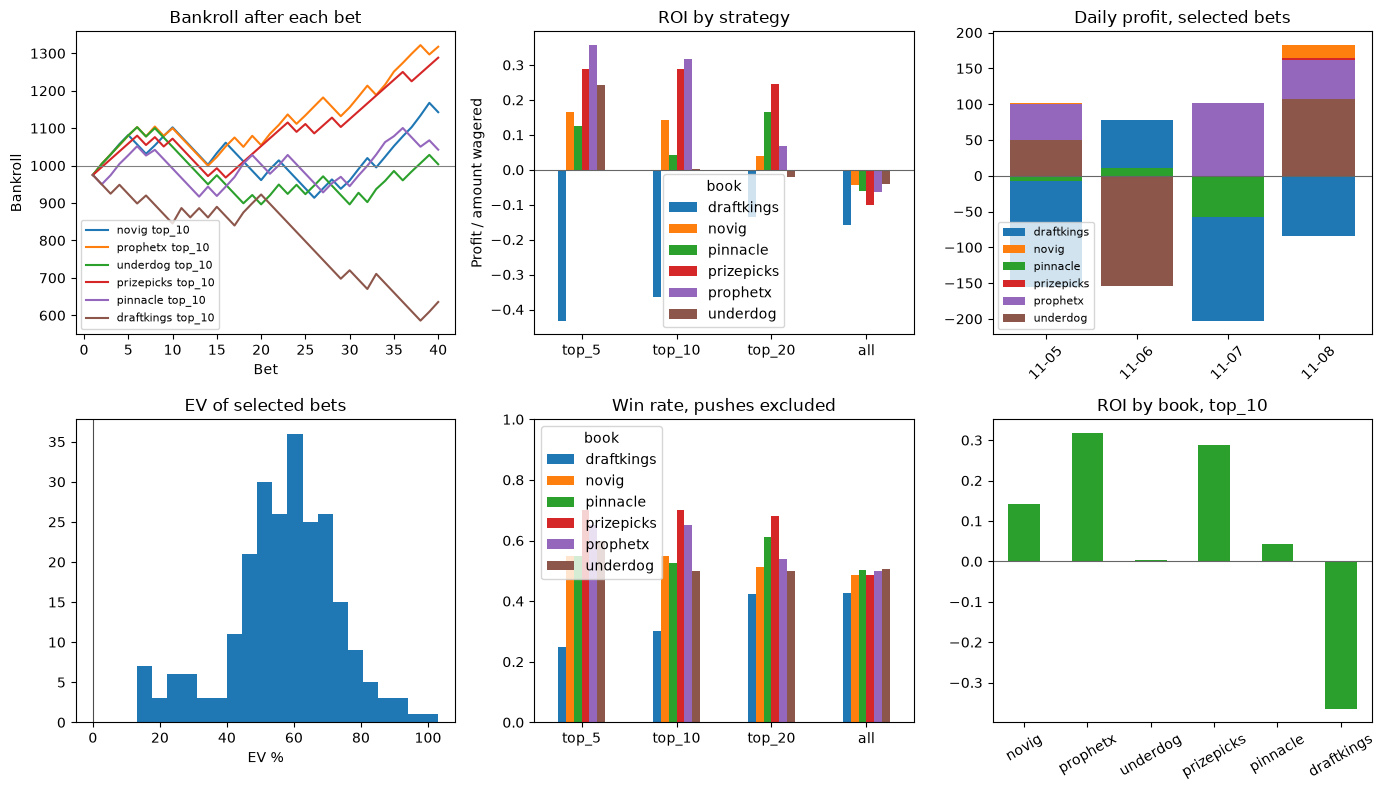

Selected strategy top_10, flat stake 25.
novig: 40 bets, profit $142.71 on $1,000.00 wagered, ROI 14.3%, bankroll $1,142.71.
prophetx: 40 bets, profit $317.60 on $1,000.00 wagered, ROI 31.8%, bankroll $1,317.60.
underdog: 40 bets, profit $3.66 on $1,000.00 wagered, ROI 0.4%, bankroll $1,003.66.
prizepicks: 40 bets, profit $288.28 on $1,000.00 wagered, ROI 28.8%, bankroll $1,288.28.
pinnacle: 40 bets, profit $42.58 on $1,000.00 wagered, ROI 4.3%, bankroll $1,042.58.
draftkings: 40 bets, profit $-364.37 on $1,000.00 wagered, ROI -36.4%, bankroll $635.63.
draftkings strategy order by ROI: top_20 -13.6%, all -15.7%, top_10 -36.4%, top_5 -43.2%
draftkings highest ROI in this sample is top_20.
novig strategy order by ROI: top_5 16.5%, top_10 14.3%, top_20 3.9%, all -4.3%
novig highest ROI in this sample is top_5.
pinnacle strategy order by ROI: top_20 16.4%, top_5 12.6%, top_10 4.3%, all -6.1%
pinnacle highest ROI in this sample is top_20.
prizepicks strategy order by ROI: top_10 28.8%, top_

In [25]:
def _selected_strategy(config: BacktestConfig) -> str:
    if config.top_n is None:
        return "all"
    return f"top_{int(config.top_n)}"


def _show_comparison(comparison: pd.DataFrame) -> None:
    shown = comparison.copy()
    shown["win_rate"] = shown["win_rate"].map(lambda value: "" if pd.isna(value) else f"{value:.1%}")
    shown["roi"] = shown["roi"].map(lambda value: "" if pd.isna(value) else f"{value:.1%}")
    shown["avg_ev"] = shown["avg_ev"].map(lambda value: "" if pd.isna(value) else f"{100 * value:.1f}%")
    shown["avg_decimal_odds"] = shown["avg_decimal_odds"].map(
        lambda value: "" if pd.isna(value) else f"{value:.2f}"
    )
    for column in ("amount_wagered", "profit", "ending_bankroll"):
        shown[column] = shown[column].map(lambda value: f"{value:,.2f}")
    display(shown)


def _show_recommendations(recommendations: pd.DataFrame) -> None:
    if recommendations.empty:
        print("no bets placed")
        return
    shown = recommendations.copy()
    shown["rank"] = shown["rank"].astype(int)
    shown["model_probability"] = shown["model_probability"].map(lambda value: f"{value:.1%}")
    shown["implied_probability"] = shown["implied_probability"].map(lambda value: f"{value:.1%}")
    shown["line"] = shown["line"].map(lambda value: f"{float(value):.1f}")
    shown["american"] = shown["american"].map(lambda value: f"{value:+.0f}")
    shown["ev"] = shown["ev"].map(lambda value: f"{100 * value:.1f}%")
    shown["stake"] = shown["stake"].map(lambda value: f"{value:,.2f}")
    shown["profit"] = shown["profit"].map(lambda value: f"{value:,.2f}")
    shown["slate_date"] = shown["slate_date"].dt.date.astype(str)
    columns = [
        "slate_date",
        "rank",
        "book",
        "game",
        "market",
        "selection",
        "line",
        "model_probability",
        "implied_probability",
        "american",
        "ev",
        "stake",
        "actual_outcome",
        "result",
        "profit",
    ]
    display(shown[columns])


def _draw(comparison, recommendations, ledgers, config: BacktestConfig) -> None:
    if comparison.empty:
        print("nothing to plot")
        return
    selected = _selected_strategy(config)
    books = list(dict.fromkeys(comparison["book"]))
    strategies = [name for name in ("top_5", "top_10", "top_20", "all") if name in set(comparison["strategy"])]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))

    ax = axes[0, 0]
    for (strategy, book), ledger in ledgers.items():
        if ledger.empty:
            continue
        if len(books) == 1 or strategy == selected:
            label = strategy if len(books) == 1 else f"{book} {strategy}"
            if len(books) > 1 and strategy != selected:
                continue
            ax.plot(range(1, len(ledger) + 1), ledger["bankroll"], label=label)
    ax.axhline(config.bankroll, color="0.5", linewidth=0.8)
    ax.set_title("Bankroll after each bet")
    ax.set_xlabel("Bet")
    ax.set_ylabel("Bankroll")
    ax.legend(fontsize=8)

    ax = axes[0, 1]
    pivot = comparison.pivot(index="strategy", columns="book", values="roi").reindex(strategies)
    pivot.plot(kind="bar", ax=ax, legend=len(books) > 1)
    ax.axhline(0, color="0.4", linewidth=0.8)
    ax.set_title("ROI by strategy")
    ax.set_ylabel("Profit / amount wagered")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

    ax = axes[0, 2]
    if recommendations.empty:
        ax.set_title("Daily profit")
    else:
        daily = (
            recommendations.groupby(["slate_date", "book"], as_index=False)["profit"].sum()
        )
        for book, frame in daily.groupby("book"):
            ax.bar(frame["slate_date"].dt.strftime("%m-%d"), frame["profit"], label=book)
        ax.axhline(0, color="0.4", linewidth=0.8)
        ax.set_title("Daily profit, selected bets")
        ax.tick_params(axis="x", rotation=45)
        if daily["book"].nunique() > 1:
            ax.legend(fontsize=8)

    ax = axes[1, 0]
    if recommendations.empty:
        ax.set_title("EV")
    else:
        ax.hist(recommendations["ev"] * 100, bins=min(20, max(5, len(recommendations))), color="C0")
        ax.axvline(0, color="0.3", linewidth=0.8)
        ax.set_title("EV of selected bets")
        ax.set_xlabel("EV %")

    ax = axes[1, 1]
    rates = comparison.pivot(index="strategy", columns="book", values="win_rate").reindex(strategies)
    rates.plot(kind="bar", ax=ax, legend=len(books) > 1)
    ax.set_title("Win rate, pushes excluded")
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

    ax = axes[1, 2]
    book_roi = comparison.loc[comparison["strategy"].eq(selected)].set_index("book")["roi"]
    book_roi.plot(kind="bar", ax=ax, color="C2", legend=False)
    ax.axhline(0, color="0.4", linewidth=0.8)
    ax.set_title(f"ROI by book, {selected}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

    fig.tight_layout()
    plt.show()


def _readout(comparison: pd.DataFrame, config: BacktestConfig) -> None:
    selected = _selected_strategy(config)
    chosen = comparison.loc[comparison["strategy"].eq(selected)]
    if chosen.empty or chosen["total_bets"].sum() == 0:
        print("No bets were placed for this configuration.")
        return
    print(f"Selected strategy {selected}, {config.stake_mode} stake {config.stake}.")
    for row in chosen.itertuples(index=False):
        roi = "n/a" if pd.isna(row.roi) else f"{row.roi:.1%}"
        print(
            f"{row.book}: {row.total_bets} bets, profit ${row.profit:,.2f} "
            f"on ${row.amount_wagered:,.2f} wagered, ROI {roi}, "
            f"bankroll ${row.ending_bankroll:,.2f}."
        )
    for book, frame in comparison.groupby("book"):
        order = frame.set_index("strategy")["roi"]
        ranked = order.sort_values(ascending=False)
        best = ranked.index[0]
        print(f"{book} strategy order by ROI: " + ", ".join(
            f"{name} {value:.1%}" for name, value in ranked.items() if pd.notna(value)
        ))
        print(f"{book} highest ROI in this sample is {best}.")


if "GRADED" not in globals() or GRADED.empty:
    print("no graded wagers. Check the exclusion counts above.")
else:
    covered = GRADED["slate_date"]
    if CONFIG.start < covered.min() or CONFIG.end > covered.max():
        print(
            "CONFIG dates extend past the simulated slates "
            f"({covered.min().date()} to {covered.max().date()}). "
            "Re-run the fit and simulate cells."
        )
    RECOMMENDATIONS, COMPARISON, LEDGERS = run_strategies(GRADED, CONFIG)
    print(
        "Top 5, top 10, top 20, and all eligible wagers. "
        "Each book starts at the same bankroll and is not mixed with another book."
    )
    _show_comparison(COMPARISON)
    print(f"Bets placed by {_selected_strategy(CONFIG)}, highest EV first within each date.")
    _show_recommendations(RECOMMENDATIONS)
    _draw(COMPARISON, RECOMMENDATIONS, LEDGERS, CONFIG)
    _readout(COMPARISON, CONFIG)


## Book sharpness

A book's expected side is the over or under with the higher closing implied
probability. The hit rate is wins divided by wins plus losses on that side.
Pushes, equal prices, and quotes with only one side are counted and left out
of the rate. The highest hit rate is the sharpest book. `hit_minus_implied`
is the hit rate minus the average implied probability of the expected side.


In [26]:
def _prop_side(selection: str) -> str:
    side = str(selection).rsplit(" ", 1)[-1].strip().lower()
    if side not in {"over", "under"}:
        raise ValueError(f"selection has no over/under side: {selection}")
    return side


def _prop_player(selection: str) -> str:
    side = _prop_side(selection)
    player = str(selection)[: -(len(side) + 1)].strip()
    if not player:
        raise ValueError(f"selection is missing a player name: {selection}")
    return player


def _configured_graded(graded: pd.DataFrame, config: BacktestConfig) -> pd.DataFrame:
    out = graded.loc[
        graded["slate_date"].ge(config.start)
        & graded["slate_date"].le(config.end)
        & graded["market"].isin(config.markets)
    ].copy()
    if config.books != ("all",):
        out = out.loc[out["book"].isin(config.books)]
    return out.reset_index(drop=True)


def _percent(value: float) -> str:
    if pd.isna(value):
        return ""
    return f"{value:.1%}"


def _book_sharpness(graded: pd.DataFrame) -> pd.DataFrame:
    """Hit rate of the side each book priced as more likely to win."""
    columns = [
        "book",
        "leans",
        "decided",
        "hits",
        "misses",
        "pushes",
        "no_lean",
        "unpaired",
        "hit_rate",
        "avg_implied",
        "hit_minus_implied",
    ]
    if graded.empty:
        return pd.DataFrame(columns=columns)
    sides = graded.copy()
    sides["line"] = sides["line"].astype(float)
    sides["game_id"] = sides["game_id"].astype(str)
    sides["side"] = sides["selection"].map(_prop_side)
    sides["player"] = sides["selection"].map(_prop_player)
    if sides["implied_probability"].isna().any() or sides["result"].isna().any():
        raise ValueError("graded close is missing a price or a result")
    keys = ["slate_date", "book", "game_id", "market", "player", "line", "side"]
    if sides.duplicated(keys).any():
        raise AssertionError("a close was graded twice on the same side")
    index = ["slate_date", "book", "game_id", "market", "player", "line"]
    implied = sides.pivot(index=index, columns="side", values="implied_probability")
    settled = sides.pivot(index=index, columns="side", values="result")
    for column in ("over", "under"):
        if column not in implied.columns:
            implied[column] = np.nan
            settled[column] = np.nan
    paired = implied["over"].notna() & implied["under"].notna()
    over_res = settled["over"].to_numpy()
    under_res = settled["under"].to_numpy()
    paired_np = paired.to_numpy()
    consistent = (
        ((over_res == "push") & (under_res == "push"))
        | ((over_res == "win") & (under_res == "loss"))
        | ((over_res == "loss") & (under_res == "win"))
    )
    if not (~paired_np | consistent).all():
        raise AssertionError("over and under settled to inconsistent results")
    # Equal prices are not a lean. PrizePicks standard lines are -119 both ways.
    lean_over = paired & implied["over"].gt(implied["under"])
    lean_under = paired & implied["under"].gt(implied["over"])
    mask = lean_over | lean_under
    picked_over = lean_over.loc[mask].to_numpy()
    leans = implied.loc[mask].drop(columns=["over", "under"]).copy()
    leans["expected_side"] = np.where(picked_over, "over", "under")
    leans["result"] = np.where(
        picked_over,
        settled.loc[mask, "over"].to_numpy(),
        settled.loc[mask, "under"].to_numpy(),
    )
    leans["implied_probability"] = np.where(
        picked_over,
        implied.loc[mask, "over"].to_numpy(),
        implied.loc[mask, "under"].to_numpy(),
    )
    if not leans.empty and not leans["result"].isin(["win", "loss", "push"]).all():
        raise ValueError("expected side settled to an unknown result")
    leans = leans.reset_index()
    coverage = pd.DataFrame(
        {
            "book": implied.index.get_level_values("book"),
            "no_lean": (paired & ~lean_over & ~lean_under).to_numpy(),
            "unpaired": (~paired).to_numpy(),
        }
    )
    rows = []
    for book, covered in coverage.groupby("book", sort=True):
        book_leans = leans.loc[leans["book"].eq(book)]
        decided = book_leans.loc[book_leans["result"].isin(["win", "loss"])]
        hits = int(decided["result"].eq("win").sum())
        misses = int(decided["result"].eq("loss").sum())
        n_decided = hits + misses
        avg_implied = (
            float(decided["implied_probability"].mean()) if n_decided else np.nan
        )
        hit_rate = np.nan if n_decided == 0 else hits / n_decided
        rows.append(
            {
                "book": book,
                "leans": int(len(book_leans)),
                "decided": n_decided,
                "hits": hits,
                "misses": misses,
                "pushes": int(book_leans["result"].eq("push").sum()),
                "no_lean": int(covered["no_lean"].sum()),
                "unpaired": int(covered["unpaired"].sum()),
                "hit_rate": hit_rate,
                "avg_implied": avg_implied,
                "hit_minus_implied": (
                    np.nan if n_decided == 0 else hit_rate - avg_implied
                ),
            }
        )
    table = pd.DataFrame(rows, columns=columns)
    return table.sort_values(
        ["hit_rate", "decided", "book"],
        ascending=[False, False, True],
        na_position="last",
        kind="mergesort",
    ).reset_index(drop=True)


if "GRADED" not in globals() or GRADED.empty:
    print("no graded wagers. Check the exclusion counts above.")
else:
    SHARPNESS_POOL = _configured_graded(GRADED, CONFIG)
    BOOK_SHARPNESS = _book_sharpness(SHARPNESS_POOL)
    print(
        f"{CONFIG.start.date()} through {CONFIG.end.date()}, "
        f"{len(SHARPNESS_POOL):,} graded sides."
    )
    if BOOK_SHARPNESS.empty:
        print("No closes in this configuration.")
    else:
        shown = BOOK_SHARPNESS.copy()
        for column in ("hit_rate", "avg_implied", "hit_minus_implied"):
            shown[column] = shown[column].map(_percent)
        display(shown)
        ranked = BOOK_SHARPNESS.dropna(subset=["hit_rate"])
        if ranked.empty:
            print("No book posted a side it expected to win.")
        else:
            best = ranked.iloc[0]
            print(
                f"Sharpest book: {best.book} at {best.hit_rate:.1%} "
                f"({int(best.hits)} of {int(best.decided)} decided leans)."
            )


2026-11-05 through 2026-11-08, 14,724 graded sides.


,book,leans,decided,hits,misses,pushes,no_lean,unpaired,hit_rate,avg_implied,hit_minus_implied
0,pinnacle,661,661,380,281,0,16,0,57.5%,58.1%,-0.6%
1,underdog,1398,1398,753,645,0,77,0,53.9%,55.7%,-1.9%
2,novig,1578,1578,837,741,0,63,149,53.0%,56.0%,-2.9%
3,prophetx,1726,1726,900,826,0,44,51,52.1%,56.7%,-4.6%
4,draftkings,0,0,0,0,0,0,1160,,,
5,prizepicks,0,0,0,0,0,1119,0,,,


Sharpest book: pinnacle at 57.5% (380 of 661 decided leans).


## Model misses

These are the bets the selected strategy placed. A bet is off when it loses.
The counts split those bets into unders and overs. The same prop at two books
counts as two bets.


In [27]:
def _side_record(bets: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for side in ("over", "under"):
        part = bets.loc[bets["side"].eq(side)]
        wins = int(part["result"].eq("win").sum())
        losses = int(part["result"].eq("loss").sum())
        pushes = int(part["result"].eq("push").sum())
        decided = wins + losses
        rows.append(
            {
                "side": side,
                "bets": int(len(part)),
                "wins": wins,
                "losses": losses,
                "pushes": pushes,
                "hit_rate": np.nan if decided == 0 else wins / decided,
            }
        )
    return pd.DataFrame(rows)


def _show_side_record(record: pd.DataFrame) -> None:
    shown = record.copy()
    shown["hit_rate"] = shown["hit_rate"].map(_percent)
    display(shown)


if "RECOMMENDATIONS" not in globals() or RECOMMENDATIONS.empty:
    print("no bets placed. Run the dashboard cell.")
elif "_prop_side" not in globals():
    print("run the book sharpness cell first.")
else:
    MODEL_BETS = RECOMMENDATIONS.copy()
    MODEL_BETS["side"] = MODEL_BETS["selection"].map(_prop_side)
    unknown = set(MODEL_BETS["result"]) - {"win", "loss", "push"}
    if unknown:
        raise ValueError(f"unknown bet result: {sorted(unknown)}")
    overs = int(MODEL_BETS["side"].eq("over").sum())
    unders = int(MODEL_BETS["side"].eq("under").sum())
    MODEL_MISSES = MODEL_BETS.loc[MODEL_BETS["result"].eq("loss")].sort_values(
        ["ev", "slate_date", "book", "selection"],
        ascending=[False, True, True, True],
        kind="mergesort",
    )
    off_over = int(MODEL_MISSES["side"].eq("over").sum())
    off_under = int(MODEL_MISSES["side"].eq("under").sum())
    print(
        f"{_selected_strategy(CONFIG)} placed {len(MODEL_BETS)} bets: "
        f"{overs} over and {unders} under. "
        f"{len(MODEL_MISSES)} lost ({off_over} over, {off_under} under)."
    )
    _show_side_record(_side_record(MODEL_BETS))
    by_market = (
        MODEL_BETS.groupby(["market", "side"], as_index=False)
        .agg(
            bets=("result", "size"),
            losses=("result", lambda values: int(values.eq("loss").sum())),
            wins=("result", lambda values: int(values.eq("win").sum())),
        )
        .sort_values(["market", "side"], kind="mergesort")
        .reset_index(drop=True)
    )
    decided = by_market["wins"] + by_market["losses"]
    by_market["hit_rate"] = np.where(decided.eq(0), np.nan, by_market["wins"] / decided)
    market_shown = by_market.drop(columns="wins").copy()
    market_shown["hit_rate"] = market_shown["hit_rate"].map(_percent)
    display(market_shown)
    if MODEL_MISSES.empty:
        print("No placed bets lost.")
    else:
        print("Bets that lost, largest EV first.")
        missed = MODEL_MISSES.copy()
        missed["model_probability"] = missed["model_probability"].map(_percent)
        missed["implied_probability"] = missed["implied_probability"].map(_percent)
        missed["line"] = missed["line"].map(lambda value: f"{float(value):.1f}")
        missed["american"] = missed["american"].map(lambda value: f"{value:+.0f}")
        missed["ev"] = missed["ev"].map(lambda value: f"{100 * value:.1f}%")
        missed["profit"] = missed["profit"].map(lambda value: f"{value:,.2f}")
        missed["slate_date"] = missed["slate_date"].dt.date.astype(str)
        display(
            missed[
                [
                    "slate_date",
                    "book",
                    "game",
                    "market",
                    "side",
                    "selection",
                    "line",
                    "model_probability",
                    "implied_probability",
                    "american",
                    "ev",
                    "actual_outcome",
                    "result",
                    "profit",
                ]
            ]
        )


top_10 placed 240 bets: 41 over and 199 under. 111 lost (29 over, 82 under).


,side,bets,wins,losses,pushes,hit_rate
0,over,41,12,29,0,29.3%
1,under,199,117,82,0,58.8%


,market,side,bets,losses,hit_rate
0,assists,over,13,7,46.2%
1,assists,under,79,34,57.0%
2,pa,under,28,12,57.1%
3,points,over,12,10,16.7%
4,points,under,29,12,58.6%
5,pr,under,10,0,100.0%
6,pra,over,8,5,37.5%
7,pra,under,31,11,64.5%
8,rebounds,over,8,7,12.5%
9,rebounds,under,22,13,40.9%


Bets that lost, largest EV first.


,slate_date,book,game,market,side,selection,line,model_probability,implied_probability,american,ev,actual_outcome,result,profit
90,2026-11-06,underdog,WAS @ ATL,rebounds,under,Zuby Ejiofor under,4.5,95.3%,46.9%,+113,103.1%,Zuby Ejiofor rebounds 5,loss,-25.00
170,2026-11-06,pinnacle,SAS @ SAC,points,under,Malik Monk under,11.5,86.7%,45.5%,+120,90.7%,Malik Monk points 12,loss,-25.00
10,2026-11-06,novig,WAS @ ATL,assists,under,CJ McCollum under,3.5,80.0%,42.9%,+133,86.4%,CJ McCollum assists 4,loss,-25.00
72,2026-11-08,prophetx,BKN @ DAL,points,over,Caleb Martin over,9.5,25.2%,13.7%,+630,83.7%,Caleb Martin points 2,loss,-25.00
50,2026-11-06,prophetx,SAS @ SAC,assists,under,Malik Monk under,3.5,87.0%,47.6%,+110,82.7%,Malik Monk assists 7,loss,-25.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
204,2026-11-05,draftkings,ORL @ PHX,points,over,Oso Ighodaro over,7.5,66.0%,57.3%,-134,15.3%,Oso Ighodaro points 2,loss,-25.00
205,2026-11-05,draftkings,MIA @ GSW,rebounds,over,Klay Thompson over,2.5,49.9%,43.5%,+130,14.8%,Klay Thompson rebounds 0,loss,-25.00
207,2026-11-05,draftkings,MIA @ GSW,points,over,Draymond Green over,5.5,52.8%,46.5%,+115,13.5%,Draymond Green points 2,loss,-25.00
208,2026-11-05,draftkings,ORL @ PHX,pra,over,Oso Ighodaro over,17.5,60.2%,53.1%,-113,13.5%,Oso Ighodaro pra 8,loss,-25.00
